**Movie Theatre  vs OTT Platform Analysis**

#####To analyze movie-watching preferences and compare theatre and OTT platforms based on audience choices, viewing frequency, and reasons for preference.

In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv('theatre_vs_ott_dataset.csv')

#Data Inspection

In [3]:
df.shape

(57, 11)

In [4]:
df.head()

,Timestamp,1. What is your age group?,2. How often do you watch movies?,3. Where do you prefer to watch movies?,4. What is your favorite movie genre?,5. What type of movie do you enjoy most?,6. Which OTT platform do you use most?,7. What is the main reason you choose OTT?,8. What is the main reason you choose Theatre?,9. How often do you go to the theatre?,10. What matters most when choosing a movie?
0,10/8/2026 19:35:00,18–25,Rarely,OTT,Comedy,Feel-good,JioHotstar,Comfort at home,Friends/Family,Once in 2–3 months,Story
1,10/9/2026 10:12:09,18–25,Monthly,Theatre,Horror,Suspenseful,JioHotstar,Comfort at home,Big screen,Rarely,Story
2,10/9/2026 15:07:01,18–25,Weekly,Both,Action,Funny,Netflix,Convenience,Big screen,More than once a month,Story
3,10/9/2026 15:54:01,NaN,Weekly,Both,Comedy,Feel-good,Netflix,Convenience,Friends/Family,Once a month,Story
4,10/9/2026 15:54:42,18–25,Weekly,Theatre,Comedy,Funny,Netflix,Comfort at home,New releases,Once a month,Comedy/Entertainment


In [5]:
df.tail()

,Timestamp,1. What is your age group?,2. How often do you watch movies?,3. Where do you prefer to watch movies?,4. What is your favorite movie genre?,5. What type of movie do you enjoy most?,6. Which OTT platform do you use most?,7. What is the main reason you choose OTT?,8. What is the main reason you choose Theatre?,9. How often do you go to the theatre?,10. What matters most when choosing a movie?
52,10/13/2026 21:34:16,18–25,Weekly,Theatre,Comedy,Feel-good,Netflix,Comfort at home,New releases,Once a month,Trailer
53,10/13/2026 21:35:43,18–25,Weekly,Theatre,Comedy,Feel-good,Netflix,Cheaper,Movie atmosphere,Once a month,Trailer
54,10/13/2026 21:36:22,Below 18,Weekly,Both,Romance,Funny,SonyLIV,Watch anytime,Movie atmosphere,Once in 2–3 months,Reviews/Ratings
55,10/13/2026 21:36:51,26–35,Weekly,Both,Horror,Scary,Netflix,Cheaper,Better sound,Once a month,Actors
56,10/13/2026 21:37:30,18–25,Monthly,Both,Action,Scary,Amazon Prime,Watch anytime,Movie atmosphere,Once a month,Reviews/Ratings


In [6]:
df.columns

Index(['Timestamp', '1. What is your age group?',
       '2. How often do you watch movies? ',
       '  3. Where do you prefer to watch movies?  ',
       '  4. What is your favorite movie genre?  ',
       '  5. What type of movie do you enjoy most?  ',
       '  6. Which OTT platform do you use most?  ',
       '  7. What is the main reason you choose OTT?  ',
       '  8. What is the main reason you choose Theatre?  ',
       '  9. How often do you go to the theatre?  ',
       '  10. What matters most when choosing a movie?  '],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 57 entries, 0 to 56
Data columns (total 11 columns):
 #   Column                                              Non-Null Count  Dtype 
---  ------                                              --------------  ----- 
 0   Timestamp                                           57 non-null     object
 1   1. What is your age group?                          56 non-null     object
 2   2. How often do you watch movies?                   57 non-null     object
 3     3. Where do you prefer to watch movies?           57 non-null     object
 4     4. What is your favorite movie genre?             57 non-null     object
 5     5. What type of movie do you enjoy most?          57 non-null     object
 6     6. Which OTT platform do you use most?            57 non-null     object
 7     7. What is the main reason you choose OTT?        56 non-null     object
 8     8. What is the main reason you choose Theatre?    57 non-null     object
 9     9. How oft

In [8]:
df.describe()

,Timestamp,1. What is your age group?,2. How often do you watch movies?,3. Where do you prefer to watch movies?,4. What is your favorite movie genre?,5. What type of movie do you enjoy most?,6. Which OTT platform do you use most?,7. What is the main reason you choose OTT?,8. What is the main reason you choose Theatre?,9. How often do you go to the theatre?,10. What matters most when choosing a movie?
count,57,56,57,57,57,57,57,56,57,57,55
unique,57,4,4,3,5,5,5,5,5,4,5
top,10/8/2026 19:35:00,18–25,Monthly,Both,Comedy,Feel-good,Netflix,More choices,Movie atmosphere,Once a month,Comedy/Entertainment
freq,1,23,27,25,16,19,22,13,17,27,14


In [9]:
df.isnull().sum()

,0
Timestamp,0
1. What is your age group?,1
2. How often do you watch movies?,0
3. Where do you prefer to watch movies?,0
4. What is your favorite movie genre?,0
5. What type of movie do you enjoy most?,0
6. Which OTT platform do you use most?,0
7. What is the main reason you choose OTT?,1
8. What is the main reason you choose Theatre?,0
9. How often do you go to the theatre?,0


In [10]:
df.duplicated().sum()

np.int64(0)

#Data Cleaning

In [12]:
df.columns = [
    'Timestamp',
    'Age_Group',
    'Watching_Frequency',
    'Viewing_Preference',
    'Favorite_Genre',
    'Movie_Type',
    'OTT_Platform',
    'OTT_Reason',
    'Theatre_Reason',
    'Theatre_Frequency',
    'Movie_Selection_Factor'
]

df.head()

,Timestamp,Age_Group,Watching_Frequency,Viewing_Preference,Favorite_Genre,Movie_Type,OTT_Platform,OTT_Reason,Theatre_Reason,Theatre_Frequency,Movie_Selection_Factor
0,10/8/2026 19:35:00,18–25,Rarely,OTT,Comedy,Feel-good,JioHotstar,Comfort at home,Friends/Family,Once in 2–3 months,Story
1,10/9/2026 10:12:09,18–25,Monthly,Theatre,Horror,Suspenseful,JioHotstar,Comfort at home,Big screen,Rarely,Story
2,10/9/2026 15:07:01,18–25,Weekly,Both,Action,Funny,Netflix,Convenience,Big screen,More than once a month,Story
3,10/9/2026 15:54:01,NaN,Weekly,Both,Comedy,Feel-good,Netflix,Convenience,Friends/Family,Once a month,Story
4,10/9/2026 15:54:42,18–25,Weekly,Theatre,Comedy,Funny,Netflix,Comfort at home,New releases,Once a month,Comedy/Entertainment


In [13]:
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

In [14]:
cols = [
    'Age_Group',
    'OTT_Reason',
    'Movie_Selection_Factor'
]

df[cols] = df[cols].fillna('Not specified')

In [15]:
df.isnull().sum()

,0
Timestamp,0
Age_Group,0
Watching_Frequency,0
Viewing_Preference,0
Favorite_Genre,0
Movie_Type,0
OTT_Platform,0
OTT_Reason,0
Theatre_Reason,0
Theatre_Frequency,0


In [16]:
df = df.drop(columns=['Timestamp','Favorite_Genre'])

In [17]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (57, 9)

Missing values:
Age_Group                 0
Watching_Frequency        0
Viewing_Preference        0
Movie_Type                0
OTT_Platform              0
OTT_Reason                0
Theatre_Reason            0
Theatre_Frequency         0
Movie_Selection_Factor    0
dtype: int64

Duplicate rows:
0

Column names:
['Age_Group', 'Watching_Frequency', 'Viewing_Preference', 'Movie_Type', 'OTT_Platform', 'OTT_Reason', 'Theatre_Reason', 'Theatre_Frequency', 'Movie_Selection_Factor']


In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 57 entries, 0 to 56
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   Age_Group               57 non-null     object
 1   Watching_Frequency      57 non-null     object
 2   Viewing_Preference      57 non-null     object
 3   Movie_Type              57 non-null     object
 4   OTT_Platform            57 non-null     object
 5   OTT_Reason              57 non-null     object
 6   Theatre_Reason          57 non-null     object
 7   Theatre_Frequency       57 non-null     object
 8   Movie_Selection_Factor  57 non-null     object
dtypes: object(9)
memory usage: 4.1+ KB


In [19]:
df.nunique()

,0
Age_Group,5
Watching_Frequency,4
Viewing_Preference,3
Movie_Type,5
OTT_Platform,5
OTT_Reason,6
Theatre_Reason,5
Theatre_Frequency,4
Movie_Selection_Factor,6


In [ ]:
for col in df.columns:
    print(col, ":", df[col].unique())

Age_Group : ['18–25' 'Not specified' 'Below 18' '26–35' 'Above 35']
Watching_Frequency : ['Rarely' 'Monthly' 'Weekly' 'Daily']
Viewing_Preference : ['OTT' 'Theatre' 'Both']
Movie_Type : ['Feel-good' 'Suspenseful' 'Funny' 'Emotional' 'Scary']
OTT_Platform : ['JioHotstar' 'Netflix' 'Amazon Prime' 'SonyLIV' 'Other']
OTT_Reason : ['Comfort at home' 'Convenience' 'Cheaper' 'More choices' 'Watch anytime'
 'Not specified']
Theatre_Reason : ['Friends/Family' 'Big screen' 'New releases' 'Movie atmosphere'
 'Better sound']
Theatre_Frequency : ['Once in 2–3 months' 'Rarely' 'More than once a month' 'Once a month']
Movie_Selection_Factor : ['Story' 'Comedy/Entertainment' 'Not specified' 'Reviews/Ratings'
 'Trailer' 'Actors']


#EDA (Exploratory Data Analysis)

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

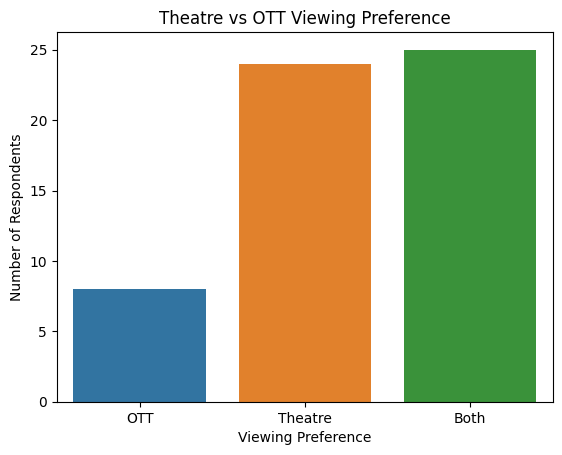

In [24]:
sns.countplot(data=df, x='Viewing_Preference',
              hue='Viewing_Preference')

plt.title('Theatre vs OTT Viewing Preference')
plt.xlabel('Viewing Preference')
plt.ylabel('Number of Respondents')
plt.show()

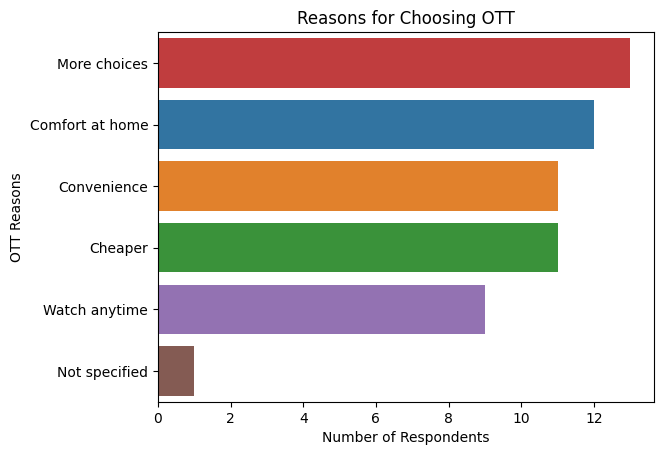

In [43]:
sns.countplot(data=df, y='OTT_Reason',
              order=df['OTT_Reason'].value_counts().index,
              hue='OTT_Reason')

plt.title('Reasons for Choosing OTT')
plt.xlabel('Number of Respondents')
plt.ylabel('OTT Reasons')
plt.show()

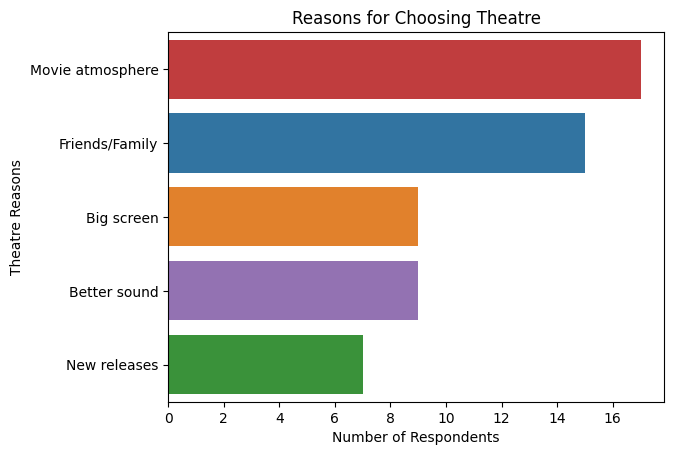

In [44]:
sns.countplot(data=df, y='Theatre_Reason',
              order=df['Theatre_Reason'].value_counts().index,
              hue='Theatre_Reason')

plt.title('Reasons for Choosing Theatre')
plt.xlabel('Number of Respondents')
plt.ylabel('Theatre Reasons')
plt.show()

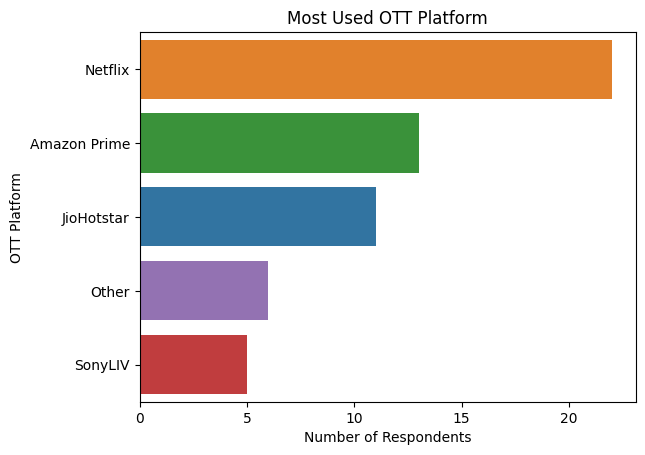

In [26]:
sns.countplot(data=df, y='OTT_Platform',
              hue='OTT_Platform',
              order=df['OTT_Platform'].value_counts().index)

plt.title('Most Used OTT Platform')
plt.xlabel('Number of Respondents')
plt.ylabel('OTT Platform')
plt.show()

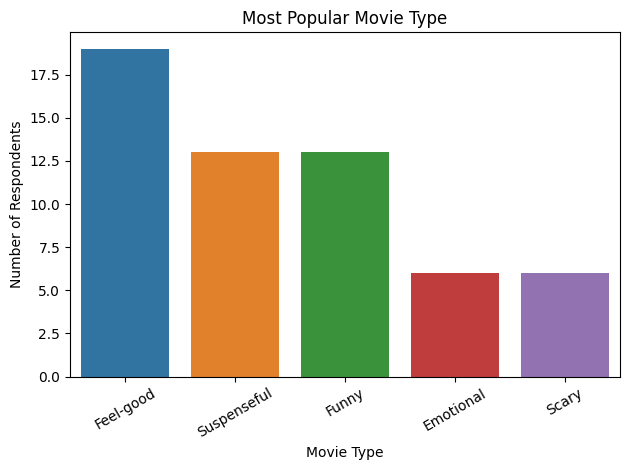

In [28]:
sns.countplot(data=df, x='Movie_Type',
              hue='Movie_Type',
              order=df['Movie_Type'].value_counts().index)

plt.title('Most Popular Movie Type')
plt.xlabel('Movie Type')
plt.ylabel('Number of Respondents')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

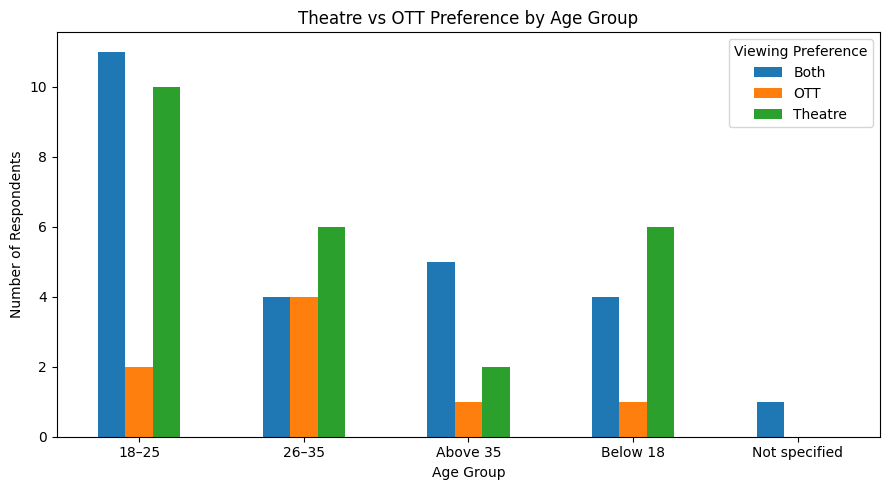

In [ ]:
age_preference = pd.crosstab(
    df['Age_Group'],
    df['Viewing_Preference']
)

age_preference.plot(kind='bar', figsize=(9, 5))

plt.title('Theatre vs OTT Preference by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Number of Respondents')
plt.legend(title='Viewing Preference')
plt.tight_layout()
plt.show()

#Feature Engineering

In [50]:
df.head()

,Age_Group,Watching_Frequency,Viewing_Preference,Movie_Type,OTT_Platform,OTT_Reason,Theatre_Reason,Theatre_Frequency,Movie_Selection_Factor
0,18–25,Rarely,OTT,Feel-good,JioHotstar,Comfort at home,Friends/Family,Once in 2–3 months,Story
1,18–25,Monthly,Theatre,Suspenseful,JioHotstar,Comfort at home,Big screen,Rarely,Story
2,18–25,Weekly,Both,Funny,Netflix,Convenience,Big screen,More than once a month,Story
3,Not specified,Weekly,Both,Feel-good,Netflix,Convenience,Friends/Family,Once a month,Story
4,18–25,Weekly,Theatre,Funny,Netflix,Comfort at home,New releases,Once a month,Comedy/Entertainment


In [53]:
df.dtypes

,0
Age_Group,object
Watching_Frequency,object
Viewing_Preference,object
Movie_Type,object
OTT_Platform,object
OTT_Reason,object
Theatre_Reason,object
Theatre_Frequency,object
Movie_Selection_Factor,object


In [62]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(sparse_output=False, dtype=int)

encoded_data = encoder.fit_transform(
    df[['Viewing_Preference']]
)

encoded_df = pd.DataFrame(
    encoded_data,
    columns=encoder.get_feature_names_out(['Viewing_Preference']),
    index=df.index
)

encoded_df.head()

,Viewing_Preference_Both,Viewing_Preference_OTT,Viewing_Preference_Theatre
0,0,1,0
1,0,0,1
2,1,0,0
3,1,0,0
4,0,0,1


In [60]:
df.to_csv('theatre_vs_ott_cleaned_dataset.csv', index=False)

**Conclusion:**

####The Theatre vs OTT analysis helps understand people's movie-watching preferences and habits. It identifies whether audiences prefer theatres, OTT platforms, or both. The analysis also highlights popular movie genres, OTT platforms, and the main reasons behind their choices. Viewing preferences may vary based on age group and watching frequency. Overall, the study provides insights into audience preferences for theatre and OTT entertainment.